# Defending Edge AI in Healthcare —Implementation


## 1. Setup

In [ ]:
import os, time, shutil, warnings, pickle, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

warnings.filterwarnings('ignore')

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {DEVICE}")

MODEL_DIR = 'saved_models'
os.makedirs(MODEL_DIR, exist_ok=True)

# 5 heartbeat classes from the MIT-BIH dataset
CLASS_NAMES = ['N (Normal)', 'S (Supraventricular)', 'V (Ventricular)',
               'F (Fusion)', 'Q (Unknown)']
CLASS_SHORT = ['N', 'S', 'V', 'F', 'Q']


Device: cuda


## 2. Load MIT-BIH Dataset & Class Weights

In [ ]:
# Download if needed
if not os.path.exists('mitbih_train.csv'):
    print("Downloading MIT-BIH dataset...")
    !pip install -q kagglehub
    import kagglehub
    path = kagglehub.dataset_download('shayanfazeli/heartbeat')
    shutil.copy(os.path.join(path, 'mitbih_train.csv'), 'mitbih_train.csv')
    shutil.copy(os.path.join(path, 'mitbih_test.csv'), 'mitbih_test.csv')
    print("Done.")

train_df = pd.read_csv('mitbih_train.csv', header=None)
test_df  = pd.read_csv('mitbih_test.csv', header=None)

X_train_all = train_df.iloc[:, :187].values.astype(np.float32)
y_train_all = train_df.iloc[:, 187].values.astype(np.int64)
X_test      = test_df.iloc[:, :187].values.astype(np.float32)
y_test      = test_df.iloc[:, 187].values.astype(np.int64)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_all, y_train_all, test_size=0.15, random_state=42, stratify=y_train_all
)

X_train = X_train[:, None, :]
X_val   = X_val[:, None, :]
X_test  = X_test[:, None, :]

# Effective-Number-of-Samples class weighting (Cui et al., 2019). Raw
# inverse-frequency weighting gives the rarest class (F, 545 samples) a
# weight ~113x that of the majority class (N) here, which pushes the model
# to over-predict rare classes and hurts precision. This scheme grows far
# more gently (~2-3x) while still correcting for the imbalance.
counts = np.bincount(y_train, minlength=5).astype(np.float32)
beta = 0.999
effective_num = 1.0 - np.power(beta, counts)
weights = torch.tensor((1.0 - beta) / effective_num, dtype=torch.float32).to(DEVICE)
weights = weights / weights.sum()

print(f"Train: {len(X_train):,} | Val: {len(X_val):,} | Test: {len(X_test):,}")
print(f"Class distribution (train): {dict(zip(CLASS_SHORT, counts.astype(int)))}")
print(f"Class weights: {dict(zip(CLASS_SHORT, weights.cpu().numpy().round(4)))}")


Using Colab cache for faster access to the 'heartbeat' dataset.
Done.
Train: 74,420 | Val: 13,134 | Test: 21,892
Class distribution (train): {'N': np.int64(61600), 'S': np.int64(1889), 'V': np.int64(4920), 'F': np.int64(545), 'Q': np.int64(5466)}
Class weights: {'N': np.float32(0.1522), 'S': np.float32(0.1793), 'V': np.float32(0.1534), 'F': np.float32(0.3622), 'Q': np.float32(0.1529)}


### MIT-BIH Dataset Description

- **Total Samples (Rows)**:
  - Training dataset: `87,554` rows (split in the code as `74,420` train and `13,134` validation)
  - Test dataset: `21,892` rows
  - Combined dataset: `109,446` heartbeats
- **Features (Columns)**:
  - `188` columns in total.
  - Columns `0` to `186` (first 187 values) represent the normalized electrocardiogram (ECG) signal values of each heartbeat.
  - Column `187` represents the ground-truth categorical label (0 to 4).
- **Missing / Null Values**:
  - There are `0` missing or null values in either the training or testing CSV files; the dataset is completely dense and fully populated.

## 3. Model Architectures

CNN1D and ResNet1D are trained too — CNN1D becomes the attacker's surrogate
model for the black-box threat scenario (Section 9), and ResNet1D is kept
purely as baseline context.

In [ ]:
class CNN1D(nn.Module):
    """Simple 1D CNN — also used later as the black-box attack surrogate."""
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv1d(1, 32, kernel_size=5, padding=2), nn.BatchNorm1d(32), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(32, 64, kernel_size=5, padding=2), nn.BatchNorm1d(64), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(64, 128, kernel_size=3, padding=1), nn.BatchNorm1d(128), nn.ReLU(),
            nn.AdaptiveAvgPool1d(1)
        )
        self.head = nn.Sequential(
            nn.Flatten(), nn.Linear(128, 64), nn.ReLU(), nn.Dropout(0.3), nn.Linear(64, 5)
        )

    def forward(self, x):
        return self.head(self.features(x))


class CNN_LSTM(nn.Module):
    """The paper's backbone: CNN for local morphology, LSTM for sequential context."""
    def __init__(self):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv1d(1, 32, kernel_size=5, padding=2), nn.BatchNorm1d(32), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(32, 64, kernel_size=5, padding=2), nn.BatchNorm1d(64), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(64, 128, kernel_size=3, padding=1), nn.BatchNorm1d(128), nn.ReLU(), nn.MaxPool1d(2)
        )
        self.lstm = nn.LSTM(input_size=128, hidden_size=64, num_layers=2,
                            batch_first=True, dropout=0.3)
        self.head = nn.Sequential(
            nn.Linear(64, 64), nn.ReLU(), nn.Dropout(0.3), nn.Linear(64, 5)
        )

    def forward(self, x):
        feats = self.cnn(x).permute(0, 2, 1)   # (batch, seq_len, 128)
        out, _ = self.lstm(feats)
        return self.head(out[:, -1, :])


class ResBlock(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv1d(channels, channels, 3, padding=1), nn.BatchNorm1d(channels), nn.ReLU(),
            nn.Conv1d(channels, channels, 3, padding=1), nn.BatchNorm1d(channels)
        )
        self.relu = nn.ReLU()

    def forward(self, x):
        return self.relu(x + self.block(x))


class ResNet1D(nn.Module):
    """Kept for baseline context only -- not used downstream."""
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv1d(1, 32, 7, stride=2, padding=3), nn.BatchNorm1d(32), nn.ReLU(), nn.MaxPool1d(2),
            ResBlock(32),
            nn.Conv1d(32, 64, 3, stride=2, padding=1), nn.BatchNorm1d(64), nn.ReLU(),
            ResBlock(64),
            nn.Conv1d(64, 128, 3, stride=2, padding=1), nn.BatchNorm1d(128), nn.ReLU(),
            ResBlock(128),
            nn.AdaptiveAvgPool1d(1), nn.Flatten(),
            nn.Linear(128, 64), nn.ReLU(), nn.Dropout(0.3), nn.Linear(64, 5)
        )

    def forward(self, x):
        return self.net(x)


MODELS = {'CNN1D': CNN1D, 'CNN_LSTM': CNN_LSTM, 'ResNet1D': ResNet1D}

# Backbone per the paper (Sections II, V, IX). CNN1D doubles as the
# black-box attack surrogate; ResNet1D is trained only for baseline context.
BACKBONE_NAME  = 'CNN_LSTM'
BACKBONE_CLASS = MODELS[BACKBONE_NAME]
SURROGATE_NAME = 'CNN1D'
print(f"Backbone (per paper): {BACKBONE_NAME}")


Backbone (per paper): CNN_LSTM


## 4. Train All Three Models

In [ ]:
BATCH_SIZE = 512
EPOCHS     = 25
LR         = 1e-3

train_loader = DataLoader(TensorDataset(torch.tensor(X_train), torch.tensor(y_train)),
                          batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(TensorDataset(torch.tensor(X_val), torch.tensor(y_val)),
                          batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(TensorDataset(torch.tensor(X_test), torch.tensor(y_test)),
                          batch_size=BATCH_SIZE, shuffle=False)


def evaluate_loss_and_f1(model, loader, criterion):
    model.eval()
    total_loss, count = 0.0, 0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            logits = model(xb)
            total_loss += criterion(logits, yb).item() * len(yb)
            count += len(yb)
            all_preds.extend(logits.argmax(dim=1).cpu().numpy())
            all_labels.extend(yb.cpu().numpy())
    return total_loss / count, f1_score(all_labels, all_preds, average='macro', zero_division=0)


def diagnose_fit(train_losses, val_losses):
    final_train, final_val = train_losses[-1], val_losses[-1]
    gap = final_val - final_train
    if final_train > 0.5 and final_val > 0.5:
        return "UNDERFITTING — both train and val loss are high."
    elif gap > 0.15:
        return "OVERFITTING — val loss much higher than train loss."
    else:
        return "GOOD FIT — train and val losses are close."


histories = {}
for name, model_cls in MODELS.items():
    pkl_path = f"{MODEL_DIR}/{name}.pkl"
    if os.path.exists(pkl_path):
        print(f"[SKIP] {name}: already saved at {pkl_path}")
        continue

    print(f"\nTraining {name}...")
    model     = model_cls().to(DEVICE)
    criterion = nn.CrossEntropyLoss(weight=weights)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', patience=2)

    train_losses, val_losses = [], []
    best_f1, best_state = 0.0, None
    t0 = time.time()

    for epoch in range(1, EPOCHS + 1):
        model.train()
        epoch_loss, epoch_count = 0.0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item() * len(yb)
            epoch_count += len(yb)

        train_loss = epoch_loss / epoch_count
        val_loss, val_f1 = evaluate_loss_and_f1(model, val_loader, criterion)
        scheduler.step(val_f1)
        train_losses.append(train_loss); val_losses.append(val_loss)

        if val_f1 > best_f1:
            best_f1, best_state = val_f1, copy.deepcopy(model.state_dict())

        if epoch % 5 == 0 or epoch == 1:
            print(f"  Epoch {epoch:>2}/{EPOCHS} | Train: {train_loss:.4f} | Val: {val_loss:.4f} | Val F1: {val_f1:.4f}")

    model.load_state_dict(best_state)
    print(f"  Done in {time.time()-t0:.0f}s | Best Val F1: {best_f1:.4f}")
    print(f"  Fit Diagnosis: {diagnose_fit(train_losses, val_losses)}")

    histories[name] = {'train_loss': train_losses, 'val_loss': val_losses}
    with open(pkl_path, 'wb') as f:
        pickle.dump(model, f)
    print(f"  Saved to {pkl_path}")



Training CNN1D...
  Epoch  1/25 | Train: 0.5575 | Val: 0.3556 | Val F1: 0.4219
  Epoch  5/25 | Train: 0.1588 | Val: 0.1766 | Val F1: 0.7631
  Epoch 10/25 | Train: 0.1235 | Val: 0.1269 | Val F1: 0.8645
  Epoch 15/25 | Train: 0.0969 | Val: 0.0970 | Val F1: 0.8826
  Epoch 20/25 | Train: 0.0919 | Val: 0.0941 | Val F1: 0.8813
  Epoch 25/25 | Train: 0.0915 | Val: 0.0940 | Val F1: 0.8797
  Done in 65s | Best Val F1: 0.8826
  Fit Diagnosis: GOOD FIT — train and val losses are close.
  Saved to saved_models/CNN1D.pkl

Training CNN_LSTM...
  Epoch  1/25 | Train: 0.7063 | Val: 0.3578 | Val F1: 0.4060
  Epoch  5/25 | Train: 0.1333 | Val: 0.1184 | Val F1: 0.8639
  Epoch 10/25 | Train: 0.0870 | Val: 0.0932 | Val F1: 0.8872
  Epoch 15/25 | Train: 0.0658 | Val: 0.0855 | Val F1: 0.8904
  Epoch 20/25 | Train: 0.0395 | Val: 0.0682 | Val F1: 0.9169
  Epoch 25/25 | Train: 0.0332 | Val: 0.0706 | Val F1: 0.9217
  Done in 80s | Best Val F1: 0.9217
  Fit Diagnosis: GOOD FIT — train and val losses are close.
 

## 5. Load Models & Baseline Benchmark

In [ ]:
def load_model_pkl(path):
    with open(path, 'rb') as f:
        model = pickle.load(f)
    model.to(DEVICE)
    model.eval()
    return model


loaded_models = {name: load_model_pkl(f"{MODEL_DIR}/{name}.pkl") for name in MODELS}
print(f"Loaded: {list(loaded_models.keys())}")


def measure_latency(model, sample, reps=200):
    model.eval()
    with torch.no_grad():
        for _ in range(20):
            model(sample)
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        for _ in range(reps):
            model(sample)
        if torch.cuda.is_available():
            torch.cuda.synchronize()
    return ((time.perf_counter() - t0) / reps) * 1000


def get_predictions(model, loader):
    model.eval()
    preds, trues = [], []
    with torch.no_grad():
        for xb, yb in loader:
            preds.extend(model(xb.to(DEVICE)).argmax(dim=1).cpu().numpy())
            trues.extend(yb.numpy())
    return np.array(trues), np.array(preds)


sample_input = torch.tensor(X_test[:1]).to(DEVICE)
bench = []
for name, model in loaded_models.items():
    trues, preds = get_predictions(model, test_loader)
    bench.append({
        'Model': name,
        'Accuracy (%)': round(accuracy_score(trues, preds) * 100, 2),
        'Macro F1':     round(f1_score(trues, preds, average='macro', zero_division=0), 4),
        'Params':       sum(p.numel() for p in model.parameters()),
        'Latency (ms)': round(measure_latency(model, sample_input), 3),
    })

df_bench = pd.DataFrame(bench).sort_values('Macro F1', ascending=False).reset_index(drop=True)
print(df_bench.to_string(index=False))
print(f"\nUsing {BACKBONE_NAME} as the backbone per the paper "
      f"(highest-scoring model here is {df_bench.iloc[0]['Model']}, kept for context only).")


Loaded: ['CNN1D', 'CNN_LSTM', 'ResNet1D']
   Model  Accuracy (%)  Macro F1  Params  Latency (ms)
ResNet1D         98.68    0.9277  170565         1.800
CNN_LSTM         98.35    0.9117  123077         1.103
   CNN1D         97.47    0.8728   44229         0.789

Using CNN_LSTM as the backbone per the paper (highest-scoring model here is ResNet1D, kept for context only).


## 6. Threat Model 1 — White-Box Attack (FGSM / PGD)

Adversary has full access to the backbone's gradients.

In [ ]:
def fgsm_attack(model, x, y, epsilon, criterion):
    was_training = model.training
    model.train()
    x_adv = x.clone().detach().requires_grad_(True)
    loss = criterion(model(x_adv), y)
    loss.backward()
    x_adv = (x_adv + epsilon * x_adv.grad.sign()).detach().clamp(0, 1)
    if not was_training: model.eval()
    return x_adv


def pgd_attack(model, x, y, epsilon, criterion, alpha=0.01, steps=10):
    was_training = model.training
    model.train()
    x_adv = x.clone().detach()
    for _ in range(steps):
        x_adv.requires_grad_(True)
        loss = criterion(model(x_adv), y)
        loss.backward()
        x_adv = (x_adv + alpha * x_adv.grad.sign()).detach()
        delta = torch.clamp(x_adv - x, min=-epsilon, max=epsilon)
        x_adv = (x + delta).clamp(0, 1)
    if not was_training: model.eval()
    return x_adv


target_model = loaded_models[BACKBONE_NAME]
target_model.eval()
criterion = nn.CrossEntropyLoss()

clean_t, clean_p = get_predictions(target_model, test_loader)
clean_acc = accuracy_score(clean_t, clean_p)

wb_results = []
for eps in [0.01, 0.05, 0.1]:
    fgsm_p, pgd_p, all_t = [], [], []
    for xb, yb in test_loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        x_fgsm = fgsm_attack(target_model, xb, yb, eps, criterion)
        x_pgd  = pgd_attack(target_model, xb, yb, eps, criterion)
        fgsm_p.extend(target_model(x_fgsm).argmax(dim=1).cpu().numpy())
        pgd_p.extend(target_model(x_pgd).argmax(dim=1).cpu().numpy())
        all_t.extend(yb.cpu().numpy())
    wb_results.append({
        'Epsilon': eps,
        'Clean Acc (%)': round(clean_acc * 100, 2),
        'FGSM Acc (%)':  round(accuracy_score(all_t, fgsm_p) * 100, 2),
        'PGD Acc (%)':   round(accuracy_score(all_t, pgd_p) * 100, 2),
    })

df_wb = pd.DataFrame(wb_results)
print(f"White-box attack on {BACKBONE_NAME} (baseline, no defense):\n")
print(df_wb.to_string(index=False))


White-box attack on CNN_LSTM (baseline, no defense):

 Epsilon  Clean Acc (%)  FGSM Acc (%)  PGD Acc (%)
    0.01          98.35         88.00        82.35
    0.05          98.35         81.90        68.02
    0.10          98.35         75.21        66.08


## 7. Threat Model 2 — Black-Box Attack (Transfer)

Adversary has no access to the backbone at all — only their own surrogate
model (CNN1D). They craft PGD examples against the surrogate and transfer
them to the real backbone.

In [ ]:
surrogate_model = loaded_models[SURROGATE_NAME]
surrogate_model.eval()
eps_bb = 0.05

bb_preds, bb_trues = [], []
for xb, yb in test_loader:
    xb, yb = xb.to(DEVICE), yb.to(DEVICE)
    x_adv = pgd_attack(surrogate_model, xb, yb, eps_bb, criterion)   # crafted on the SURROGATE
    bb_preds.extend(target_model(x_adv).argmax(dim=1).cpu().numpy())  # evaluated on the BACKBONE
    bb_trues.extend(yb.cpu().numpy())

bb_acc_baseline = accuracy_score(bb_trues, bb_preds)
print(f"Black-box transfer attack ({SURROGATE_NAME} -> {BACKBONE_NAME}, eps={eps_bb}): "
      f"{bb_acc_baseline*100:.2f}% accuracy under attack")


Black-box transfer attack (CNN1D -> CNN_LSTM, eps=0.05): 85.46% accuracy under attack


## 8. Adversarial Training — Reference / Ablation

The paper's actual proposal folds adversarial training *into* every
federated round (Section 11). This centralized version is a reference
point only, to see how much of the improvement comes from adversarial
training alone versus the full federated pipeline.

In [ ]:
def train_adversarial(model_cls, train_loader, val_loader, epochs=25, epsilon=0.05, lr=1e-3):
    """50% clean + 50% PGD-perturbed samples per batch, per the paper's Step 1."""
    model = model_cls().to(DEVICE)
    criterion = nn.CrossEntropyLoss(weight=weights)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', patience=2)

    train_losses, val_losses = [], []
    best_f1, best_state = 0.0, None

    for epoch in range(1, epochs + 1):
        model.train()
        epoch_loss, epoch_count = 0.0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            half = len(xb) // 2
            x_adv = pgd_attack(model, xb[half:], yb[half:], epsilon, criterion)
            x_mixed = torch.cat([xb[:half], x_adv], dim=0)
            y_mixed = torch.cat([yb[:half], yb[half:]], dim=0)
            optimizer.zero_grad()
            loss = criterion(model(x_mixed), y_mixed)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item() * len(y_mixed)
            epoch_count += len(y_mixed)

        train_loss = epoch_loss / epoch_count
        val_loss, val_f1 = evaluate_loss_and_f1(model, val_loader, criterion)
        scheduler.step(val_f1)
        train_losses.append(train_loss); val_losses.append(val_loss)
        if val_f1 > best_f1:
            best_f1, best_state = val_f1, copy.deepcopy(model.state_dict())
        if epoch % 5 == 0 or epoch == 1:
            print(f"  Epoch {epoch:>2}/{epochs} | Train: {train_loss:.4f} | Val: {val_loss:.4f} | Val F1: {val_f1:.4f}")

    model.load_state_dict(best_state)
    return model, {'train_loss': train_losses, 'val_loss': val_losses}


print(f"Training centralized adversarially-trained {BACKBONE_NAME} (reference only)...\n")
adv_model, adv_history = train_adversarial(BACKBONE_CLASS, train_loader, val_loader, epochs=EPOCHS)
print(f"\nFit Diagnosis: {diagnose_fit(adv_history['train_loss'], adv_history['val_loss'])}")

with open(f"{MODEL_DIR}/{BACKBONE_NAME}_adversarial_reference.pkl", 'wb') as f:
    pickle.dump(adv_model, f)


Training centralized adversarially-trained CNN_LSTM (reference only)...

  Epoch  1/25 | Train: 0.7873 | Val: 0.6810 | Val F1: 0.1811
  Epoch  5/25 | Train: 0.3184 | Val: 0.2118 | Val F1: 0.6086
  Epoch 10/25 | Train: 0.2130 | Val: 0.1420 | Val F1: 0.8259
  Epoch 15/25 | Train: 0.1858 | Val: 0.1147 | Val F1: 0.8577
  Epoch 20/25 | Train: 0.1776 | Val: 0.1132 | Val F1: 0.8558
  Epoch 25/25 | Train: 0.1736 | Val: 0.1112 | Val F1: 0.8581

Fit Diagnosis: GOOD FIT — train and val losses are close.


## 9. Integrated Federated Pipeline
One `federated_round()` function implements the paper's Section VII loop,
run once per round for every node:

1. **Local adversarial training** — PGD-mixed, 50/50 clean+adversarial (Step 1)
2. **Client-side norm clipping** — bounds each update before it leaves the
   node, calibrated from real clean-update norms rather than a guessed
   constant (Step 3's defensive purpose; see the note above on why this
   happens before encryption, not on ciphertext)
3. **Homomorphic encryption** — each (clipped, size-weighted) update is
   encrypted before leaving the node (Step 2)
4. **Server aggregation** — ciphertexts are summed; the server decrypts
   only the aggregate, never an individual node's update (Step 3/4)

A poisoned node uses a **sign-flip + scale attack**: it inverts and
amplifies its own true update, trying to drag the global model in the
wrong direction — the standard way to stress-test norm-based clipping
defenses in federated learning literature.

The same function runs three scenarios so the comparison is apples-to-apples:
no poisoning, poisoning **with** the clipping defense (the paper's proposed
system), and poisoning **without** it (why the defense matters).

In [ ]:
class MockPaillierEncryption:
    """
    Simulates additive homomorphic encryption: Enc(a) + Enc(b) decrypts to
    (approximately) a + b, via negligible added noise, standing in for a
    real Paillier-style scheme. This lets the server sum encrypted updates
    and decrypt only the aggregate -- it never sees any individual node's
    plaintext update, which is the actual privacy property Section VII is
    after.
    """
    def __init__(self, noise_scale=1e-8):
        self.noise_scale = noise_scale

    def encrypt(self, tensor):
        return tensor + torch.randn_like(tensor) * self.noise_scale

    def decrypt(self, tensor):
        return tensor

    def encrypted_sum(self, encrypted_tensors):
        return sum(encrypted_tensors)


phe = MockPaillierEncryption()


def get_update(global_model, local_model):
    return {k: local_model.state_dict()[k].float() - global_model.state_dict()[k].float()
            for k in global_model.state_dict()}


def update_norm(update):
    return torch.sqrt(sum((v ** 2).sum() for v in update.values())).item()


def clip_update(update, thresholds):
    """Per-tensor clip, calibrated from clean update norms (see calibration below)."""
    clipped = {}
    for k, v in update.items():
        t = thresholds.get(k, 1.0)
        n = v.norm()
        clipped[k] = v * (t / n) if n > t else v
    return clipped


def boost_attack(update, boost=8.0):
    """Sign-flip + scale: a compromised node tries to drag the global model
    the wrong way and dominate the weighted average."""
    return {k: -boost * v for k, v in update.items()}


def local_adversarial_train(model, loader, epochs, epsilon, lr):
    """Step 1: PGD-mixed adversarial training at the node."""
    criterion = nn.CrossEntropyLoss(weight=weights)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    for _ in range(epochs):
        model.train()
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            half = len(xb) // 2
            x_adv = pgd_attack(model, xb[half:], yb[half:], epsilon, criterion)
            x_mixed = torch.cat([xb[:half], x_adv], dim=0)
            y_mixed = torch.cat([yb[:half], yb[half:]], dim=0)
            optimizer.zero_grad()
            criterion(model(x_mixed), y_mixed).backward()
            optimizer.step()
    return model


def federated_round(global_model, node_loaders, node_sizes, round_lr,
                     poison_frac=0.0, thresholds=None, boost=8.0):
    """One full round: local AT -> (poison) -> clip -> encrypt -> aggregate -> decrypt -> apply."""
    total = sum(node_sizes)
    num_poisoned = int(len(node_loaders) * poison_frac)
    encrypted_updates = []
    norms_before, norms_after, n_clipped = [], [], 0

    t0 = time.perf_counter()
    for i, loader in enumerate(node_loaders):
        local_model = local_adversarial_train(copy.deepcopy(global_model), loader,
                                               LOCAL_EPOCHS, FED_EPSILON, round_lr)
        update = get_update(global_model, local_model)

        if i < num_poisoned:
            update = boost_attack(update, boost=boost)

        n0 = update_norm(update)
        norms_before.append(n0)

        if thresholds is not None:
            update = clip_update(update, thresholds)
            n1 = update_norm(update)
            if n1 < n0 - 1e-6:
                n_clipped += 1
            norms_after.append(n1)
        else:
            norms_after.append(n0)

        weight = node_sizes[i] / total
        weighted_update = {k: v * weight for k, v in update.items()}
        encrypted_updates.append({k: phe.encrypt(v) for k, v in weighted_update.items()})

    agg_encrypted = {k: phe.encrypted_sum([u[k] for u in encrypted_updates]) for k in encrypted_updates[0]}
    agg_update = {k: phe.decrypt(v) for k, v in agg_encrypted.items()}
    round_time_ms = (time.perf_counter() - t0) * 1000

    new_state = global_model.state_dict()
    for k in new_state:
        new_state[k] = new_state[k].float() + agg_update[k]
    global_model.load_state_dict(new_state)

    return global_model, {
        'avg_norm_before_clip': float(np.mean(norms_before)),
        'avg_norm_after_clip':  float(np.mean(norms_after)),
        'nodes_clipped':        n_clipped,
        'round_time_ms':        round_time_ms,
    }


# --- Node setup ---
NUM_NODES       = 5
FED_ROUNDS      = 15
LOCAL_EPOCHS    = 3
FED_EPSILON     = 0.05
FED_LR_DECAY    = 0.97
POISON_FRACTION = 0.2   # 1 of 5 nodes compromised

def split_data_for_nodes(X, y, num_nodes):
    indices = np.random.permutation(len(X))
    shards = np.array_split(indices, num_nodes)
    return [DataLoader(TensorDataset(torch.tensor(X[s]), torch.tensor(y[s])),
                        batch_size=BATCH_SIZE, shuffle=True) for s in shards]

np.random.seed(42)
node_loaders = split_data_for_nodes(X_train, y_train, NUM_NODES)
node_sizes   = [len(l.dataset) for l in node_loaders]
print(f"{NUM_NODES} nodes | sizes: {node_sizes}")

# --- Calibrate clip thresholds from real clean-update norms ---
print("\nCalibrating clip thresholds from clean update norms...")
calib_model = BACKBONE_CLASS().to(DEVICE)
sample_norms = {}
for loader in node_loaders[:3]:
    lm = local_adversarial_train(copy.deepcopy(calib_model), loader, LOCAL_EPOCHS, FED_EPSILON, LR)
    upd = get_update(calib_model, lm)
    for k, v in upd.items():
        sample_norms.setdefault(k, []).append(v.norm().item())
CLIP_THRESHOLDS = {k: max(float(np.percentile(v, 90)) * 1.5, 1e-3) for k, v in sample_norms.items()}
print(f"Calibrated {len(CLIP_THRESHOLDS)} thresholds (median = {np.median(list(CLIP_THRESHOLDS.values())):.4f})")

# --- Run the three paper-aligned scenarios with the SAME pipeline function ---
SCENARIOS = {
    'Federated — Clean (no poisoning)':            dict(poison_frac=0.0,             thresholds=None),
    'Federated — Poisoned + Clipped (proposed)':   dict(poison_frac=POISON_FRACTION, thresholds=CLIP_THRESHOLDS),
    'Federated — Poisoned + No Clip (undefended)': dict(poison_frac=POISON_FRACTION, thresholds=None),
}

fed_models, fed_histories = {}, {}
for label, cfg in SCENARIOS.items():
    print(f"\n=== {label} ===")
    g_model = BACKBONE_CLASS().to(DEVICE)
    hist = []
    for rnd in range(1, FED_ROUNDS + 1):
        round_lr = LR * (FED_LR_DECAY ** (rnd - 1))
        g_model, diag = federated_round(g_model, node_loaders, node_sizes, round_lr, **cfg)

        val_loss, val_f1 = evaluate_loss_and_f1(g_model, val_loader, nn.CrossEntropyLoss())
        trues, preds = get_predictions(g_model, test_loader)
        diag.update({'round': rnd, 'val_f1': val_f1, 'test_acc': accuracy_score(trues, preds)})
        hist.append(diag)

        if rnd % 5 == 0 or rnd == 1:
            print(f"  Round {rnd:>2}/{FED_ROUNDS} | Val F1: {val_f1:.4f} | Test Acc: {diag['test_acc']*100:.2f}% | "
                  f"Norm: {diag['avg_norm_before_clip']:.3f} -> {diag['avg_norm_after_clip']:.3f} | "
                  f"Clipped: {diag['nodes_clipped']}/{NUM_NODES}")

    fed_models[label] = g_model
    fed_histories[label] = pd.DataFrame(hist)

print("\nAll three federated scenarios complete.")


5 nodes | sizes: [14884, 14884, 14884, 14884, 14884]

Calibrating clip thresholds from clean update norms...
Calibrated 33 thresholds (median = 0.5065)

=== Federated — Clean (no poisoning) ===
  Round  1/15 | Val F1: 0.1811 | Test Acc: 82.76% | Norm: 1714.777 -> 1714.777 | Clipped: 0/5
  Round  5/15 | Val F1: 0.5693 | Test Acc: 93.76% | Norm: 1714.735 -> 1714.735 | Clipped: 0/5
  Round 10/15 | Val F1: 0.6773 | Test Acc: 95.68% | Norm: 1714.732 -> 1714.732 | Clipped: 0/5
  Round 15/15 | Val F1: 0.8405 | Test Acc: 96.72% | Norm: 1714.732 -> 1714.732 | Clipped: 0/5

=== Federated — Poisoned + Clipped (proposed) ===
  Round  1/15 | Val F1: 0.1811 | Test Acc: 82.76% | Norm: 4115.473 -> 1886.259 | Clipped: 1/5
  Round  5/15 | Val F1: 0.0256 | Test Acc: 6.80% | Norm: 4115.376 -> 1886.227 | Clipped: 1/5
  Round 10/15 | Val F1: 0.1811 | Test Acc: 82.76% | Norm: 4115.372 -> 1886.226 | Clipped: 1/5
  Round 15/15 | Val F1: 0.1811 | Test Acc: 82.76% | Norm: 4115.372 -> 1886.225 | Clipped: 1/5

===

### Federated Convergence — All Scenarios

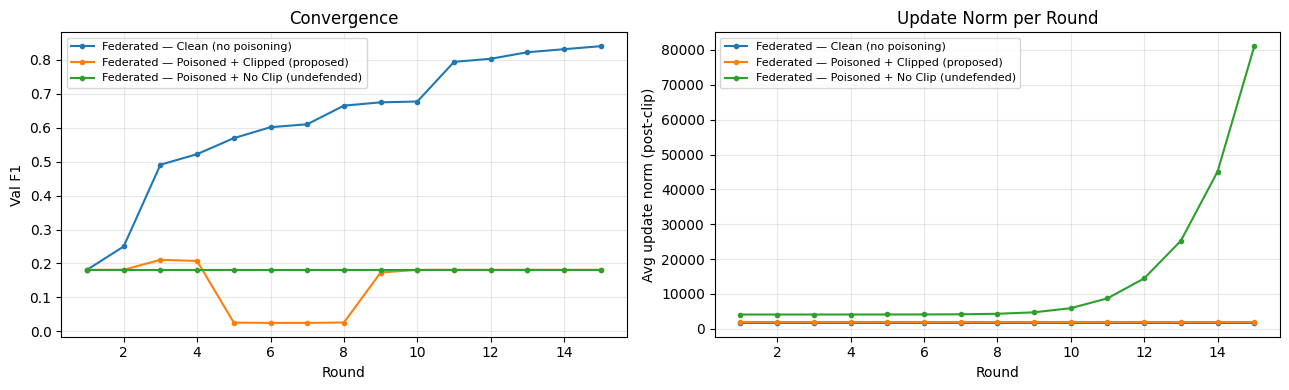

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for label, hist in fed_histories.items():
    axes[0].plot(hist['round'], hist['val_f1'], marker='o', label=label, markersize=3)
    axes[1].plot(hist['round'], hist['avg_norm_after_clip'], marker='o', label=label, markersize=3)

axes[0].set_xlabel('Round'); axes[0].set_ylabel('Val F1'); axes[0].set_title('Convergence')
axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)

axes[1].set_xlabel('Round'); axes[1].set_ylabel('Avg update norm (post-clip)')
axes[1].set_title('Update Norm per Round'); axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


## 10. Final Evaluation — All Scenarios & Both Threat Models

In [ ]:
epsilon = 0.05

def evaluate_full(model, label):
    model.eval()
    trues, preds = get_predictions(model, test_loader)
    clean_acc = accuracy_score(trues, preds)
    clean_f1  = f1_score(trues, preds, average='macro', zero_division=0)

    pgd_p, all_t = [], []
    bb_p, bb_t = [], []
    for xb, yb in test_loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        x_pgd = pgd_attack(model, xb, yb, epsilon, criterion)                 # white-box
        x_bb  = pgd_attack(surrogate_model, xb, yb, epsilon, criterion)       # black-box (crafted on surrogate)
        pgd_p.extend(model(x_pgd).argmax(dim=1).cpu().numpy())
        bb_p.extend(model(x_bb).argmax(dim=1).cpu().numpy())
        all_t.extend(yb.cpu().numpy())
        bb_t.extend(yb.cpu().numpy())

    return {
        'Model':                       label,
        'Clean Acc (%)':               round(clean_acc * 100, 2),
        'Macro F1':                    round(clean_f1, 4),
        'White-box PGD Acc (%)':       round(accuracy_score(all_t, pgd_p) * 100, 2),
        'Black-box Transfer Acc (%)':  round(accuracy_score(bb_t, bb_p) * 100, 2),
        'Params':                      sum(p.numel() for p in model.parameters()),
        'Latency (ms)':                round(measure_latency(model, sample_input), 3),
    }


final_rows = [
    evaluate_full(loaded_models[BACKBONE_NAME], f'Baseline {BACKBONE_NAME}'),
    evaluate_full(adv_model, f'Reference: Centralized AT {BACKBONE_NAME}'),
]
for label, model in fed_models.items():
    final_rows.append(evaluate_full(model, label))

df_final = pd.DataFrame(final_rows)
print("=" * 110)
print("                              FINAL EVALUATION — ALL SCENARIOS")
print("=" * 110)
print(df_final.to_string(index=False))
print("=" * 110)


NameError: name 'loaded_models' is not defined

In [ ]:
"""
architecture_figures.py
-----------------------
Paper-ready diagrams for "Defending Edge AI in Healthcare".
Needs only matplotlib (no GPU, no dataset). Run:  python architecture_figures.py
Outputs (PNG @300 dpi + vector PDF) go to ./figures/

Fig 1  System architecture        (what the notebook actually implements)
Fig 2  System / data flow         (one federated round + final evaluation)
Fig 3  CNN-LSTM backbone          (layer-by-layer, tensor shapes)
Fig 4  Threat model               (white-box, black-box, poisoning)

Anything the paper proposes but the notebook does NOT evaluate (blockchain audit,
5G/LoRaWAN, Jetson deployment, clinician dashboard) is drawn with a DASHED outline
so reviewers can see exactly what is implemented vs. conceptual.
"""
import os
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Polygon, Rectangle

OUT_DIR = "figures"
os.makedirs(OUT_DIR, exist_ok=True)

plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 9, "figure.dpi": 150})

# colour palette: (fill, edge)
BLUE   = ("#DCE9F7", "#2F5D8A")
ORANGE = ("#FCE8CF", "#B7701E")
GREEN  = ("#DDF0DD", "#3E7B3E")
RED    = ("#F8DADA", "#A63A3A")
PURPLE = ("#E6DFF3", "#5B4A8A")
GRAY   = ("#F2F2F2", "#7A7A7A")
TEAL   = ("#D8F0EE", "#2A7F7A")


# ------------------------------------------------------------------ helpers
def box(ax, x, y, w, h, text, c=BLUE, fs=8.5, bold_first=True, dashed=False, lw=1.4):
    """Rounded box centred at (x, y). First line of `text` is bold."""
    p = FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.02,rounding_size=0.12",
                       fc=c[0], ec=c[1], lw=lw, ls="--" if dashed else "-", zorder=2)
    ax.add_patch(p)
    lines = text.split("\n")
    if bold_first and len(lines) > 1:
        n = len(lines)
        step = fs * 0.0215
        y0 = y + (n - 1) * step / 2
        ax.text(x, y0, lines[0], ha="center", va="center", fontsize=fs, fontweight="bold", color=c[1], zorder=3)
        for i, ln in enumerate(lines[1:], 1):
            ax.text(x, y0 - i * step, ln, ha="center", va="center", fontsize=fs - 1, color="#222", zorder=3)
    else:
        ax.text(x, y, text, ha="center", va="center", fontsize=fs, fontweight="bold" if bold_first else "normal",
                color=c[1] if bold_first else "#222", zorder=3)


def diamond(ax, x, y, w, h, text, c=ORANGE, fs=8):
    ax.add_patch(Polygon([(x, y + h / 2), (x + w / 2, y), (x, y - h / 2), (x - w / 2, y)],
                         closed=True, fc=c[0], ec=c[1], lw=1.4, zorder=2))
    ax.text(x, y, text, ha="center", va="center", fontsize=fs, fontweight="bold", color=c[1], zorder=3)


def oval(ax, x, y, w, h, text, fc, ec):
    from matplotlib.patches import Ellipse
    ax.add_patch(Ellipse((x, y), w, h, fc=fc, ec=ec, lw=1.4, zorder=2))
    ax.text(x, y, text, ha="center", va="center", fontsize=9, fontweight="bold", color="white", zorder=3)


def arrow(ax, p1, p2, c="#333", ls="-", rad=0.0, lw=1.3, label=None, lpos=0.5, loff=(0, 0), fs=7.5):
    a = FancyArrowPatch(p1, p2, arrowstyle="-|>", mutation_scale=11, lw=lw, color=c, ls=ls,
                        connectionstyle=f"arc3,rad={rad}", zorder=1, shrinkA=0, shrinkB=0)
    ax.add_patch(a)
    if label:
        mx = p1[0] + (p2[0] - p1[0]) * lpos + loff[0]
        my = p1[1] + (p2[1] - p1[1]) * lpos + loff[1]
        ax.text(mx, my, label, fontsize=fs, ha="center", va="center", color=c,
                bbox=dict(fc="white", ec="none", pad=0.6), zorder=4)


def panel(ax, x0, y0, x1, y1, title, c=GRAY, dashed=False):
    ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fc=c[0], ec=c[1], lw=1.2,
                           ls="--" if dashed else "-", alpha=0.55, zorder=0))
    ax.text((x0 + x1) / 2, y1 - 0.22, title, ha="center", va="center", fontsize=9.5, fontweight="bold", color=c[1])


def canvas(w, h, xlim, ylim):
    fig, ax = plt.subplots(figsize=(w, h))
    ax.set_xlim(*xlim); ax.set_ylim(*ylim); ax.axis("off")
    return fig, ax


def save(fig, name):
    for ext in ("png", "pdf"):
        fig.savefig(f"{OUT_DIR}/{name}.{ext}", dpi=300, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    print(f"saved {OUT_DIR}/{name}.png / .pdf")


# ------------------------------------------------------------------ Fig 1
def fig_system_architecture():
    fig, ax = canvas(13, 7.8, (0, 13), (0, 7.8))

    # three tiers
    panel(ax, 0.2, 1.3, 4.3, 7.3, "TIER 1 · Edge Node (x5)", BLUE)
    panel(ax, 4.9, 1.3, 8.2, 7.3, "TIER 2 · Secure Update Channel", ORANGE)
    panel(ax, 8.8, 1.3, 12.8, 7.3, "TIER 3 · Aggregation Server", GREEN)

    # Tier 1
    box(ax, 2.25, 6.3, 3.5, 0.75, "Wearable ECG Sensor\nMIT-BIH heartbeat, 187 samples", BLUE)
    box(ax, 2.25, 5.2, 3.5, 0.75, "Pre-processing\nMin-max scaling to [0, 1]", BLUE)
    box(ax, 2.25, 4.1, 3.5, 0.75, "CNN-LSTM Classifier\n5 classes: N / S / V / F / Q", PURPLE)
    box(ax, 2.25, 2.95, 3.5, 0.85, "Local Adversarial Training\nPGD  eps=0.05, 50% clean + 50% adv.\n3 local epochs / round", RED)
    box(ax, 2.25, 1.95, 3.5, 0.5, "Local update  dW = W_local - W_global", BLUE, bold_first=False, fs=8)
    for y1, y2 in [(5.92, 5.58), (4.82, 4.48), (3.72, 3.38), (2.52, 2.2)]:
        arrow(ax, (2.25, y1), (2.25, y2))

    # Tier 2
    box(ax, 6.55, 5.6, 2.8, 0.9, "Norm Clipping\nper-tensor threshold,\ncalibrated on clean updates", ORANGE)
    box(ax, 6.55, 4.1, 2.8, 0.9, "Homomorphic Encryption\nadditive (Paillier-style)\nsimulated in notebook", ORANGE)
    box(ax, 6.55, 2.6, 2.8, 0.75, "Weighted update\nw_i = n_i / sum(n)", ORANGE)
    arrow(ax, (6.55, 5.15), (6.55, 4.55))
    arrow(ax, (6.55, 3.65), (6.55, 2.98))
    # update leaves node: elbow into clipping box
    ax.plot([4.0, 4.6], [1.95, 1.95], color="#333", lw=1.3, zorder=1)
    ax.plot([4.6, 4.6], [1.95, 5.6], color="#333", lw=1.3, zorder=1)
    arrow(ax, (4.6, 5.6), (5.15, 5.6))
    ax.text(4.6, 3.6, "update\nleaves node", fontsize=7, color="#333", ha="center", va="center", rotation=90,
            bbox=dict(fc="white", ec="none", pad=0.5))

    # Tier 3
    box(ax, 10.8, 5.6, 3.4, 0.9, "Encrypted Aggregation\nsum of ciphertexts, server never\nsees a single node's update", GREEN)
    box(ax, 10.8, 4.1, 3.4, 0.9, "Decrypt Aggregate Only\nfederated average of 5 updates", GREEN)
    box(ax, 10.8, 2.6, 3.4, 0.9, "Updated Global Model\nbroadcast to all nodes\n15 rounds, LR decay 0.97", GREEN)
    arrow(ax, (10.8, 5.15), (10.8, 4.55))
    arrow(ax, (10.8, 3.65), (10.8, 3.05))
    ax.plot([7.95, 8.5], [2.6, 2.6], color="#333", lw=1.3, zorder=1)
    ax.plot([8.5, 8.5], [2.6, 5.6], color="#333", lw=1.3, zorder=1)
    arrow(ax, (8.5, 5.6), (9.1, 5.6))
    ax.text(8.5, 4.0, "ciphertext", fontsize=7, color="#333", ha="center", va="center", rotation=90,
            bbox=dict(fc="white", ec="none", pad=0.5))
    # broadcast back
    ax.plot([10.8, 10.8], [2.15, 1.55], color=GREEN[1], lw=1.3, ls="--", zorder=1)
    ax.plot([10.8, 2.25], [1.55, 1.55], color=GREEN[1], lw=1.3, ls="--", zorder=1)
    arrow(ax, (2.25, 1.55), (2.25, 1.7), c=GREEN[1])
    ax.text(6.55, 1.55, "global model broadcast (next round)", fontsize=7.5, color=GREEN[1], ha="center", va="center",
            bbox=dict(fc="white", ec="none", pad=0.6), zorder=4)

    # Conceptual (not evaluated)
    box(ax, 6.55, 0.65, 6.4, 0.5, "Blockchain audit log  ·  5G/LoRaWAN  ·  Jetson Nano  ·  Clinician dashboard", GRAY,
        bold_first=False, dashed=True, fs=8)
    ax.text(6.55, 0.2, "dashed = proposed in the paper, not evaluated in the notebook", fontsize=7.5,
            style="italic", ha="center", color="#555")

    # Attack markers
    ax.text(0.55, 3.2, "A1", fontsize=8, fontweight="bold", color="white", ha="center", va="center",
            bbox=dict(boxstyle="circle,pad=0.25", fc=RED[1], ec="none"), zorder=5)
    ax.text(0.55, 4.4, "A2", fontsize=8, fontweight="bold", color="white", ha="center", va="center",
            bbox=dict(boxstyle="circle,pad=0.25", fc=RED[1], ec="none"), zorder=5)
    ax.text(5.15, 5.6, "A3", fontsize=8, fontweight="bold", color="white", ha="center", va="center",
            bbox=dict(boxstyle="circle,pad=0.25", fc=RED[1], ec="none"), zorder=5)
    ax.text(6.5, 7.55, "A1/A2 inference-time evasion: A1 white-box FGSM/PGD, A2 black-box transfer (CNN1D surrogate)      A3 poisoning (sign-flip x8)", fontsize=8, ha="center", color=RED[1])

    ax.set_title("Fig. 1  System architecture of the defended federated edge-AI pipeline", fontsize=11,
                 fontweight="bold", pad=26)
    save(fig, "fig1_system_architecture")


# ------------------------------------------------------------------ Fig 2
def fig_system_flow():
    fig, ax = canvas(9.8, 13.6, (0, 9.8), (-0.6, 13.2))
    cx = 3.6

    oval(ax, cx, 12.7, 1.8, 0.55, "START", "#2E9E5B", "#1F6B3D")
    box(ax, cx, 11.75, 4.6, 0.7, "Load MIT-BIH heartbeat data\n109,446 beats -> 74,420 train / 13,134 val / 21,892 test", BLUE)
    box(ax, cx, 10.75, 4.6, 0.7, "Partition training set across 5 edge nodes (IID)\nInitialise global CNN-LSTM", BLUE)
    box(ax, cx, 9.75, 4.6, 0.7, "Calibrate clip thresholds\n90th percentile of clean update norms x 1.5", ORANGE)

    # loop container
    ax.add_patch(Rectangle((0.35, 2.55), 7.2, 6.55, fc="none", ec="#888", ls="--", lw=1.1, zorder=0))
    ax.text(0.5, 8.95, "Federated round  r = 1 ... 15", fontsize=8.5, fontweight="bold", color="#555", va="center")

    box(ax, cx, 8.45, 4.2, 0.6, "Broadcast global model to all nodes", GREEN, bold_first=False)
    box(ax, cx, 7.55, 4.2, 0.75, "Local adversarial training (each node)\nPGD eps=0.05, 50% clean / 50% adversarial", RED)
    diamond(ax, cx, 6.45, 3.0, 1.05, "Node\ncompromised?", ORANGE)
    box(ax, 6.5, 6.45, 1.7, 0.75, "Sign-flip\nupdate x(-8)", RED, fs=8)
    box(ax, cx, 5.2, 4.2, 0.6, "Compute update  dW  and clip its norm", ORANGE, bold_first=False)
    box(ax, cx, 4.3, 4.2, 0.6, "Encrypt weighted update (additive HE)", ORANGE, bold_first=False)
    box(ax, cx, 3.4, 4.2, 0.65, "Server: sum ciphertexts, decrypt aggregate,\napply to global model", GREEN)

    diamond(ax, cx, 1.95, 3.0, 0.95, "r = 15 ?", ORANGE)
    box(ax, cx, 0.85, 4.6, 0.75, "Final evaluation\nclean acc / macro-F1, white-box PGD, black-box transfer", PURPLE)
    oval(ax, cx, -0.2, 1.5, 0.45, "END", "#C0392B", "#8E2A20")

    # main flow arrows
    for y1, y2 in [(12.42, 12.1), (11.4, 11.1), (10.4, 10.1), (9.4, 8.78), (8.15, 7.95), (7.17, 6.98),
                   (5.92, 5.5), (4.9, 4.6), (4.0, 3.73), (3.07, 2.43)]:
        arrow(ax, (cx, y1), (cx, y2))
    ax.text(cx + 0.18, 5.92, "No", fontsize=7.5, color="#333")
    arrow(ax, (cx + 1.5, 6.45), (5.65, 6.45))
    ax.text(5.4, 6.68, "Yes", fontsize=7.5, color="#333", ha="center")
    ax.plot([6.5, 6.5], [6.07, 5.2], color="#333", lw=1.3, zorder=1)
    arrow(ax, (6.5, 5.2), (cx + 2.1, 5.2))
    # No loop -> back to broadcast
    arrow(ax, (cx - 1.5, 1.95), (0.15, 1.95), c="#333")
    ax.plot([0.15, 0.15], [1.95, 8.45], color="#333", lw=1.3, zorder=1)
    arrow(ax, (0.15, 8.45), (cx - 2.1, 8.45))
    ax.text(0.85, 2.12, "No: next round", fontsize=7.5, color="#333")
    ax.text(cx + 0.18, 1.45, "Yes", fontsize=7.5, color="#333")
    arrow(ax, (cx, 0.47), (cx, 0.04))

    # conceptual sidebar
    box(ax, 8.5, 11.2, 2.3, 1.6, "Deployment layer\n(not evaluated)\nBlockchain audit,\n5G / LoRaWAN,\nJetson Nano, dashboard", GRAY,
        dashed=True, fs=7.5)

    ax.set_title("Fig. 2  System flow: one federated round with adversarial, poisoning and privacy defences",
                 fontsize=10.5, fontweight="bold", pad=10)
    save(fig, "fig2_system_flow")


# ------------------------------------------------------------------ Fig 3
def fig_model_architecture():
    fig, ax = canvas(14, 4.6, (0, 14), (0, 4.6))
    y = 2.3
    specs = [
        ("Input\nECG beat", "1 x 187", GRAY, 1.15),
        ("Conv1D\nk=5, 32 ch\nBN + ReLU\nMaxPool(2)", "32 x 93", BLUE, 1.35),
        ("Conv1D\nk=5, 64 ch\nBN + ReLU\nMaxPool(2)", "64 x 46", BLUE, 1.35),
        ("Conv1D\nk=3, 128 ch\nBN + ReLU\nMaxPool(2)", "128 x 23", BLUE, 1.35),
        ("Permute\nto (steps,\nfeatures)", "23 x 128", GRAY, 1.35),
        ("LSTM\n2 layers\nhidden 64\ndropout 0.3", "last step: 64", PURPLE, 1.35),
        ("FC 64\nReLU\nDropout 0.3", "64", ORANGE, 1.15),
        ("FC 5\nSoftmax", "5 classes", GREEN, 1.05),
    ]
    x = 0.8
    centres = []
    for title, shape, c, w in specs:
        box(ax, x + w / 2, y, w, 1.9, title, c, fs=8, bold_first=False)
        ax.text(x + w / 2, y - 1.3, shape, ha="center", fontsize=8, color=c[1], fontweight="bold")
        centres.append((x, x + w))
        x += w + 0.38
    for i in range(len(centres) - 1):
        arrow(ax, (centres[i][1], y), (centres[i + 1][0], y))

    # brackets
    def bracket(x0, x1, label, c):
        ax.plot([x0, x0, x1, x1], [3.5, 3.65, 3.65, 3.5], color=c, lw=1.3)
        ax.text((x0 + x1) / 2, 3.85, label, ha="center", fontsize=9, fontweight="bold", color=c)
    bracket(centres[1][0], centres[3][1], "CNN feature extractor  (local morphology)", BLUE[1])
    bracket(centres[5][0], centres[5][1], "Temporal context", PURPLE[1])
    bracket(centres[6][0], centres[7][1], "Classifier head", ORANGE[1])
    ax.text(7.0, 0.35, "123,077 trainable parameters   ·   classes: N (Normal), S (Supraventricular), V (Ventricular), F (Fusion), Q (Unknown)",
            ha="center", fontsize=8.5, color="#444")
    ax.set_title("Fig. 3  CNN-LSTM backbone used on every edge node", fontsize=11, fontweight="bold", pad=8)
    save(fig, "fig3_cnn_lstm_architecture")


# ------------------------------------------------------------------ Fig 4
def fig_threat_model():
    fig, ax = canvas(12.5, 5.6, (0, 12.5), (0, 5.6))
    rows = [
        (4.45, "A1  White-box evasion", "Attacker has full gradient access to the deployed CNN-LSTM",
         ["Clean ECG x", "FGSM / PGD\neps in {0.01, 0.05, 0.1}", "Adversarial x'", "CNN-LSTM\n(deployed)", "Wrong class"], RED),
        (2.75, "A2  Black-box transfer", "Attacker only owns a surrogate model (CNN1D)",
         ["Clean ECG x", "PGD on CNN1D\nsurrogate, eps=0.05", "Adversarial x'", "CNN-LSTM\n(deployed)", "Wrong class"], ORANGE),
        (1.05, "A3  Model poisoning", "1 of 5 federated nodes is compromised",
         ["Honest local\nupdate dW", "Sign-flip\nx(-8)", "Poisoned\nupdate", "Server\naggregation", "Corrupted\nglobal model"], PURPLE),
    ]
    for y, title, sub, steps, c in rows:
        ax.text(0.2, y + 0.62, title, fontsize=10, fontweight="bold", color=c[1])
        ax.text(3.45, y + 0.62, sub, fontsize=8, color="#444", style="italic")
        xs = [1.2, 3.55, 6.0, 8.4, 10.9]
        for i, (xx, s) in enumerate(zip(xs, steps)):
            last = i == len(xs) - 1
            box(ax, xx, y - 0.1, 1.95, 0.8, s, RED if last else (c if i in (1,) else BLUE), bold_first=False, fs=8)
        for i in range(4):
            arrow(ax, (xs[i] + 0.98, y - 0.1), (xs[i + 1] - 0.98, y - 0.1))
    ax.text(6.25, 0.05, "Defences:  A1/A2 -> adversarial training (PGD, 50/50)      A3 -> norm clipping + encrypted aggregation",
            ha="center", fontsize=8.5, color=GREEN[1], fontweight="bold")
    ax.set_title("Fig. 4  Threat model evaluated in the study", fontsize=11, fontweight="bold", pad=10)
    save(fig, "fig4_threat_model")


if __name__ == "__main__":
    fig_system_architecture()
    fig_system_flow()
    fig_model_architecture()
    fig_threat_model()

saved figures/fig1_system_architecture.png / .pdf
saved figures/fig2_system_flow.png / .pdf
saved figures/fig3_cnn_lstm_architecture.png / .pdf
saved figures/fig4_threat_model.png / .pdf


In [ ]:
"""
paper_results.py
----------------
Tables + plots for "Defending Edge AI in Healthcare".

All functions here take plain numpy arrays / pandas DataFrames (no torch), so they can be
tested anywhere.  The notebook glue that extracts predictions from your models is in
`notebook_cells.py`  (paste those cells at the end of your notebook).

Outputs go to ./figures (PNG 300 dpi + PDF) and ./tables (CSV + LaTeX + PNG).
"""
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score, confusion_matrix,
                             balanced_accuracy_score, matthews_corrcoef, roc_curve, auc,
                             precision_recall_curve, average_precision_score)
from sklearn.preprocessing import label_binarize

FIG_DIR, TAB_DIR = "figures", "tables"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(TAB_DIR, exist_ok=True)

CLASS_SHORT = ["N", "S", "V", "F", "Q"]
CLASS_NAMES = ["N (Normal)", "S (Supraventricular)", "V (Ventricular)", "F (Fusion)", "Q (Unknown)"]

# colour-blind-safe palette (Okabe-Ito)
PAL = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#000000"]

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25,
    "legend.frameon": False, "figure.dpi": 120,
})


def _save(fig, name):
    for ext in ("png", "pdf"):
        fig.savefig(f"{FIG_DIR}/{name}.{ext}", dpi=300, bbox_inches="tight", facecolor="white")
    print(f"saved {FIG_DIR}/{name}.png / .pdf")


# =====================================================================================
#  TABLES
# =====================================================================================
LOWER_IS_BETTER = ("latency", "params", "size", "drop", "time", "gflops")


def _is_lower_better(col):
    return any(k in col.lower() for k in LOWER_IS_BETTER)


def classification_table(preds: dict, extras: pd.DataFrame = None):
    """
    preds  : {model_name: (y_true, y_pred)}
    extras : optional DataFrame indexed by model name with columns such as
             'Params', 'Size (KB)', 'Latency (ms)'
    Fields (all computed on the same test set):
      Accuracy, Balanced Acc, Macro Precision/Recall/F1, Weighted F1, MCC
    Macro metrics treat the 5 heartbeat classes equally, so they expose weak minority-class
    performance that plain accuracy hides on this ~83% 'Normal' test set.
    """
    rows = []
    for name, (yt, yp) in preds.items():
        p, r, f, _ = precision_recall_fscore_support(yt, yp, average="macro", zero_division=0)
        rows.append({
            "Model": name,
            "Accuracy (%)": accuracy_score(yt, yp) * 100,
            "Balanced Acc (%)": balanced_accuracy_score(yt, yp) * 100,
            "Macro Precision (%)": p * 100,
            "Macro Recall (%)": r * 100,
            "Macro F1 (%)": f * 100,
            "Weighted F1 (%)": f1_score(yt, yp, average="weighted", zero_division=0) * 100,
            "MCC": matthews_corrcoef(yt, yp),
        })
    df = pd.DataFrame(rows)
    if extras is not None:
        df = df.merge(extras.reset_index().rename(columns={"index": "Model"}), on="Model", how="left")
    return df


def per_class_table(y_true, y_pred, class_names=CLASS_NAMES):
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=range(len(class_names)), zero_division=0)
    return pd.DataFrame({"Class": class_names, "Precision (%)": p * 100, "Recall (%)": r * 100,
                         "F1 (%)": f * 100, "Support": s.astype(int)})


def robustness_table(df_final: pd.DataFrame, clean_col="Clean Acc (%)",
                     wb_col="White-box PGD Acc (%)", bb_col="Black-box Transfer Acc (%)"):
    """Adds accuracy-drop columns (percentage points) to the notebook's df_final."""
    d = df_final.copy()
    d["PGD Drop (pp)"] = d[clean_col] - d[wb_col]
    d["Transfer Drop (pp)"] = d[clean_col] - d[bb_col]
    return d


def _fmt(v, col):
    if isinstance(v, (int, np.integer)):
        return f"{v:,}"
    if isinstance(v, (float, np.floating)):
        if "mcc" in col.lower():
            return f"{v:.3f}"
        if "params" in col.lower() or "support" in col.lower():
            return f"{int(v):,}"
        if "latency" in col.lower():
            return f"{v:.2f}"
        return f"{v:.2f}"
    return str(v)


def _best_mask(df, bold_best=True):
    mask = pd.DataFrame(False, index=df.index, columns=df.columns)
    if not bold_best:
        return mask
    for c in df.columns[1:]:
        if pd.api.types.is_numeric_dtype(df[c]) and df[c].nunique() > 1 and c.lower() not in ("support",):
            best = df[c].min() if _is_lower_better(c) else df[c].max()
            mask[c] = df[c] == best
    return mask


def save_table(df: pd.DataFrame, name: str, caption: str, bold_best=True, png=True):
    """Writes tables/<name>.csv, tables/<name>.tex (booktabs) and tables/<name>.png"""
    df.to_csv(f"{TAB_DIR}/{name}.csv", index=False)
    mask = _best_mask(df, bold_best)

    # ---- LaTeX (own writer, no jinja2 needed)
    def tex_esc(s):
        return (str(s).replace("&", r"\&").replace("%", r"\%").replace("_", r"\_").replace("#", r"\#"))
    cols = list(df.columns)
    lines = [r"\begin{table}[t]", r"\centering", rf"\caption{{{tex_esc(caption)}}}", rf"\label{{tab:{name}}}",
             r"\small", r"\begin{tabular}{l" + "r" * (len(cols) - 1) + "}", r"\toprule",
             " & ".join(tex_esc(c) for c in cols) + r" \\", r"\midrule"]
    for i, row in df.iterrows():
        cells = []
        for c in cols:
            t = tex_esc(_fmt(row[c], c))
            cells.append(rf"\textbf{{{t}}}" if mask.loc[i, c] else t)
        lines.append(" & ".join(cells) + r" \\")
    lines += [r"\bottomrule", r"\end{tabular}", r"\end{table}"]
    open(f"{TAB_DIR}/{name}.tex", "w").write("\n".join(lines))

    # ---- PNG in the same booktabs look as the reference tables
    if png:
        txt = [[_fmt(row[c], c) for c in cols] for _, row in df.iterrows()]
        heads = [c.replace(" (", "\n(") for c in cols]
        widths = [max(max(len(l) for l in h.split("\n")) * 0.50, max(len(r[j]) for r in txt) * 0.52) + 0.9
                  for j, h in enumerate(heads)]
        W, rowh, headh = sum(widths), 0.6, 1.0
        H = headh + rowh * len(df) + 1.2
        fig, ax = plt.subplots(figsize=(W / 3.0, H / 3.0))
        ax.set_xlim(0, W); ax.set_ylim(0, H); ax.axis("off")
        y = H - 0.4
        ax.text(0.1, y, caption, fontsize=9, va="center", ha="left")
        ytop = y - 0.45
        ax.hlines(ytop, 0, W, color="black", lw=1.4)
        yh = ytop - headh / 2
        x = 0
        for j, h in enumerate(heads):
            ax.text(x + (0.1 if j == 0 else widths[j] / 2), yh, h, fontsize=8, fontweight="bold", va="center",
                    ha="left" if j == 0 else "center", linespacing=1.15)
            x += widths[j]
        ybot = ytop - headh
        ax.hlines(ybot, 0, W, color="black", lw=0.8)
        y = ybot
        for i, r in enumerate(txt):
            y -= rowh
            x = 0
            for j, c in enumerate(cols):
                ax.text(x + (0.1 if j == 0 else widths[j] / 2), y + rowh / 2, r[j], fontsize=8, va="center",
                        ha="left" if j == 0 else "center", fontweight="bold" if mask.iloc[i, j] else "normal")
                x += widths[j]
        ax.hlines(y, 0, W, color="black", lw=1.4)
        fig.savefig(f"{TAB_DIR}/{name}.png", dpi=300, bbox_inches="tight", facecolor="white")
        plt.close(fig)
    print(f"saved tables/{name}.csv / .tex / .png")


# =====================================================================================
#  CONFUSION MATRICES
# =====================================================================================
def _draw_cm(ax, cm, labels, title, normalize=True, cmap="Blues", fs=9):
    cmn = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
    im = ax.imshow(cmn if normalize else cm, cmap=cmap, vmin=0, vmax=1 if normalize else None)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            val = cmn[i, j]
            txt = f"{cm[i, j]:,}\n({val * 100:.1f}%)" if normalize else f"{cm[i, j]:,}"
            ax.text(j, i, txt, ha="center", va="center", fontsize=fs,
                    color="white" if val > 0.55 else "black")
    ax.set_xticks(range(len(labels))); ax.set_yticks(range(len(labels)))
    ax.set_xticklabels(labels); ax.set_yticklabels(labels)
    ax.set_xlabel("Predicted label"); ax.set_ylabel("True label"); ax.set_title(title)
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(True)
    return im


def plot_confusion(y_true, y_pred, title, name, labels=CLASS_SHORT, normalize=True):
    """Single 5-class confusion matrix: counts + row-normalised percentage (= per-class recall)."""
    cm = confusion_matrix(y_true, y_pred, labels=range(len(labels)))
    fig, ax = plt.subplots(figsize=(5.6, 4.8))
    im = _draw_cm(ax, cm, labels, title, normalize)
    cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cb.set_label("Row-normalised (recall)" if normalize else "Count")
    _save(fig, name)
    return cm


def plot_confusion_grid(preds: dict, name, labels=CLASS_SHORT, ncols=3, suptitle=None):
    """Side-by-side normalised confusion matrices, one panel per model / scenario."""
    n = len(preds)
    ncols = min(ncols, n)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.6 * ncols, 4.2 * nrows), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, (k, (yt, yp)) in zip(axes.ravel(), preds.items()):
        ax.axis("on")
        cm = confusion_matrix(yt, yp, labels=range(len(labels)))
        acc = accuracy_score(yt, yp) * 100
        _draw_cm(ax, cm, labels, f"{k}\nAcc {acc:.2f}%", True, fs=7.5)
    if suptitle:
        fig.suptitle(suptitle, fontsize=12, fontweight="bold")
    fig.tight_layout()
    _save(fig, name)


def plot_binary_confusion(y_true, y_pred, title, name):
    """
    Normal (N) vs Anomaly (S/V/F/Q) view, in the same style as the reference paper's Fig. 5.
    Anomaly is the clinically important class, so report its recall explicitly.
    """
    yt = (np.asarray(y_true) != 0).astype(int)
    yp = (np.asarray(y_pred) != 0).astype(int)
    cm = confusion_matrix(yt, yp, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    rec = tp / max(tp + fn, 1)
    prec = tp / max(tp + fp, 1)
    fig, ax = plt.subplots(figsize=(5.2, 4.4))
    _draw_cm(ax, cm, ["Normal (0)", "Anomaly (1)"], title, True, fs=11)
    ax.set_xlabel(f"Predicted label\nAnomaly recall {rec * 100:.1f}%   precision {prec * 100:.1f}%")
    _save(fig, name)
    return {"TN": tn, "FP": fp, "FN": fn, "TP": tp, "anomaly_recall": rec, "anomaly_precision": prec}


# =====================================================================================
#  CURVES / BAR CHARTS
# =====================================================================================
def plot_roc_pr(y_true, y_prob, name, labels=CLASS_SHORT, title_suffix=""):
    """One-vs-rest ROC (left) and precision-recall (right) per class. y_prob: (N, 5) softmax."""
    k = len(labels)
    Y = label_binarize(y_true, classes=range(k))
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.4))
    for i in range(k):
        if Y[:, i].sum() == 0:
            continue
        fpr, tpr, _ = roc_curve(Y[:, i], y_prob[:, i])
        axes[0].plot(fpr, tpr, color=PAL[i], lw=1.8, label=f"{labels[i]} (AUC {auc(fpr, tpr):.3f})")
        pr, rc, _ = precision_recall_curve(Y[:, i], y_prob[:, i])
        axes[1].plot(rc, pr, color=PAL[i], lw=1.8, label=f"{labels[i]} (AP {average_precision_score(Y[:, i], y_prob[:, i]):.3f})")
    axes[0].plot([0, 1], [0, 1], "k--", lw=0.8)
    axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title=f"ROC (one-vs-rest){title_suffix}")
    axes[1].set(xlabel="Recall", ylabel="Precision", title=f"Precision-Recall{title_suffix}", ylim=(0, 1.02))
    for a in axes:
        a.legend(loc="lower right" if a is axes[0] else "lower left", fontsize=8)
    fig.tight_layout()
    _save(fig, name)


def plot_training_curves(histories: dict, name="fig_training_curves"):
    """histories: {model_name: {'train_loss': [...], 'val_loss': [...]}}"""
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 4))
    for i, (k, h) in enumerate(histories.items()):
        ep = np.arange(1, len(h["train_loss"]) + 1)
        axes[0].plot(ep, h["train_loss"], color=PAL[i], lw=1.8, label=k)
        axes[1].plot(ep, h["val_loss"], color=PAL[i], lw=1.8, label=k)
    axes[0].set(xlabel="Epoch", ylabel="Weighted CE loss", title="Training loss")
    axes[1].set(xlabel="Epoch", ylabel="Weighted CE loss", title="Validation loss")
    axes[0].legend(); fig.tight_layout()
    _save(fig, name)


def plot_epsilon_sweep(df_wb: pd.DataFrame, name="fig_epsilon_sweep"):
    """df_wb columns: Epsilon, Clean Acc (%), FGSM Acc (%), PGD Acc (%) (your notebook's df_wb)."""
    fig, ax = plt.subplots(figsize=(5.8, 4.2))
    eps = df_wb["Epsilon"].values
    ax.plot([0] + list(eps), [df_wb["Clean Acc (%)"].iloc[0]] + list(df_wb["FGSM Acc (%)"]), "o-", color=PAL[0], label="FGSM")
    ax.plot([0] + list(eps), [df_wb["Clean Acc (%)"].iloc[0]] + list(df_wb["PGD Acc (%)"]), "s-", color=PAL[1], label="PGD-10")
    ax.axhline(df_wb["Clean Acc (%)"].iloc[0], color="gray", ls=":", lw=1, label="Clean")
    ax.set(xlabel=r"Perturbation budget $\epsilon$ ($L_\infty$)", ylabel="Accuracy (%)", title="White-box attack strength")
    ax.legend()
    _save(fig, name)


def plot_robustness_bars(df_final: pd.DataFrame, name="fig_robustness_comparison", label_col="Model",
                         cols=("Clean Acc (%)", "White-box PGD Acc (%)", "Black-box Transfer Acc (%)")):
    """Grouped bars: clean / white-box / black-box accuracy for every scenario."""
    n, m = len(df_final), len(cols)
    w = 0.8 / m
    fig, ax = plt.subplots(figsize=(max(7.5, 1.9 * n), 4.6))
    for j, c in enumerate(cols):
        bars = ax.bar(np.arange(n) + (j - (m - 1) / 2) * w, df_final[c], w, color=PAL[j], label=c.replace(" Acc (%)", ""))
        for b in bars:
            ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 1, f"{b.get_height():.1f}", ha="center", fontsize=7)
    labels = [l.replace(" — ", "\n").replace("Reference: ", "Ref: ").replace(" (", "\n(") for l in df_final[label_col]]
    ax.set_xticks(range(n)); ax.set_xticklabels(labels, fontsize=7.5)
    ax.set(ylabel="Accuracy (%)", ylim=(0, 112), title="Clean vs adversarial accuracy per scenario")
    ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.28))
    _save(fig, name)


def plot_perclass_f1_heatmap(preds: dict, name="fig_perclass_f1_heatmap", labels=CLASS_SHORT):
    """Rows = scenarios, columns = classes, cell = per-class F1. Reveals collapsed / majority-only models."""
    M = np.array([f1_score(yt, yp, labels=range(len(labels)), average=None, zero_division=0) * 100
                  for yt, yp in preds.values()])
    fig, ax = plt.subplots(figsize=(1.2 * len(labels) + 4.5, 0.65 * len(preds) + 1.6))
    im = ax.imshow(M, cmap="YlGnBu", vmin=0, vmax=100, aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, f"{M[i, j]:.1f}", ha="center", va="center", fontsize=9, color="white" if M[i, j] > 60 else "black")
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels)
    ax.set_yticks(range(len(preds))); ax.set_yticklabels(list(preds.keys()), fontsize=8)
    ax.set_title("Per-class F1 (%) by scenario"); ax.grid(False)
    fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
    _save(fig, name)


def plot_federated_convergence(fed_histories: dict, name="fig_federated_convergence"):
    """fed_histories: {scenario: DataFrame[round, val_f1, test_acc, avg_norm_before_clip, avg_norm_after_clip, nodes_clipped]}"""
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.1))
    for i, (k, h) in enumerate(fed_histories.items()):
        short = k.replace("Federated — ", "")
        axes[0].plot(h["round"], h["val_f1"], "o-", ms=3, color=PAL[i], label=short)
        axes[1].plot(h["round"], h["test_acc"] * 100, "o-", ms=3, color=PAL[i], label=short)
        axes[2].plot(h["round"], h["avg_norm_before_clip"], "o-", ms=3, color=PAL[i], label=short + " (raw)")
        if (h["avg_norm_after_clip"] != h["avg_norm_before_clip"]).any():
            axes[2].plot(h["round"], h["avg_norm_after_clip"], "x--", ms=4, color=PAL[i], label=short + " (clipped)")
    axes[0].set(xlabel="Round", ylabel="Validation macro-F1", title="Convergence (macro-F1)")
    axes[1].set(xlabel="Round", ylabel="Test accuracy (%)", title="Convergence (accuracy)")
    axes[2].set(xlabel="Round", ylabel="Mean update L2 norm", title="Update norm before / after clipping", yscale="log")
    axes[0].legend(fontsize=8); axes[2].legend(fontsize=7)
    fig.tight_layout()
    _save(fig, name)


def plot_tradeoff(df_bench: pd.DataFrame, name="fig_accuracy_latency_tradeoff", metric="Macro F1 (%)"):
    """Accuracy/F1 vs latency, bubble area = parameter count."""
    fig, ax = plt.subplots(figsize=(5.8, 4.4))
    for i, r in df_bench.reset_index(drop=True).iterrows():
        ax.scatter(r["Latency (ms)"], r[metric], s=r["Params"] / 250, color=PAL[i], alpha=0.75, edgecolor="k", lw=0.8)
        ax.annotate(f"{r['Model']}\n{int(r['Params']):,} params", (r["Latency (ms)"], r[metric]),
                    textcoords="offset points", xytext=(8, 8), fontsize=8)
    ax.set(xlabel="Inference latency (ms / sample, GPU)", ylabel=metric, title="Accuracy vs latency (bubble = parameters)")
    ax.margins(0.25)
    _save(fig, name)


def plot_class_distribution(y_train, y_test, weights, name="fig_class_distribution", labels=CLASS_SHORT):
    """Class imbalance in train/test and the effective-number class weights used in the loss."""
    ctr = np.bincount(y_train, minlength=len(labels))
    cte = np.bincount(y_test, minlength=len(labels))
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 4))
    x = np.arange(len(labels))
    axes[0].bar(x - 0.2, ctr, 0.4, color=PAL[0], label="Train")
    axes[0].bar(x + 0.2, cte, 0.4, color=PAL[1], label="Test")
    axes[0].set_yscale("log"); axes[0].set_xticks(x); axes[0].set_xticklabels(labels)
    axes[0].set(ylabel="Heartbeats (log scale)", title="Class distribution"); axes[0].legend()
    for i, c in enumerate(ctr):
        axes[0].text(i - 0.2, c * 1.15, f"{c:,}", ha="center", fontsize=7)
    axes[1].bar(x, weights, color=PAL[2])
    for i, w in enumerate(weights):
        axes[1].text(i, w + 0.005, f"{w:.3f}", ha="center", fontsize=8)
    axes[1].set_xticks(x); axes[1].set_xticklabels(labels)
    axes[1].set(ylabel="Normalised weight", title="Effective-number class weights (beta=0.999)")
    fig.tight_layout()
    _save(fig, name)


def plot_adversarial_example(x_clean, x_adv, true_label, pred_clean, pred_adv, eps, name="fig_adversarial_example",
                             labels=CLASS_SHORT):
    """One heartbeat: clean vs PGD-perturbed signal and the (amplified) perturbation."""
    x_clean, x_adv = np.asarray(x_clean).ravel(), np.asarray(x_adv).ravel()
    fig, axes = plt.subplots(2, 1, figsize=(7.5, 4.6), sharex=True, gridspec_kw={"height_ratios": [3, 1.2]})
    axes[0].plot(x_clean, color=PAL[0], lw=1.6, label=f"Clean  (pred {labels[pred_clean]})")
    axes[0].plot(x_adv, color=PAL[1], lw=1.2, ls="--", label=f"PGD eps={eps}  (pred {labels[pred_adv]})")
    axes[0].set(ylabel="Normalised amplitude", title=f"True class {labels[true_label]}: adversarial perturbation on an ECG beat")
    axes[0].legend(loc="upper right")
    axes[1].plot(x_adv - x_clean, color="#555", lw=1)
    axes[1].set(xlabel="Sample index (187 samples)", ylabel="Perturbation")
    fig.tight_layout()
    _save(fig, name)